# Сравнение результатов лабораторных работ 1–5

В текущем отчёте представлены результаты лабораторной №1 — исследование KNN
для классификации кредитных заявок и регрессии прочности бетона.
Сопоставлены исходные и улучшенные модели sklearn, собственные реализации и наивные модели Dummy.

Классификация выполнена на Loan Approval Classification Data, целевой признак — `loan_status`.
Регрессия выполнена на Concrete Compressive Strength, целевой признак — `strength`, МПа.

В пределах каждой задачи использованы одинаковые исходные признаки и контрольное разбиение.
Качество классификации оценивается прежде всего по F1, качество регрессии — по MAE.
Время обучения и предсказания рассмотрено отдельно от качества.

### Результаты экспериментов
В таблице указан состав представленных лабораторных работ.
Результаты отдельных моделей объединены по задаче, алгоритму и варианту реализации.

In [1]:
# Ноутбук можно открыть из корня или из lab_1.
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
ROOT = Path.cwd() if (Path.cwd() / "lab_1").is_dir() else Path.cwd().parent
required = {"lab", "algorithm", "model", "implementation", "stage", "task", "dataset", "target", "feature_set",
            "dataset_sha", "split_sha", "protocol_id", "n_train", "n_test", "fit_seconds", "predict_seconds"}
frames, status = [], []
for number in range(1, 6):
    file = ROOT / f"lab_{number}" / "results" / "metrics.csv"
    status.append({"lab": number, "status": "результаты доступны" if file.exists() else "результаты отсутствуют"})
    if file.exists():
        frame = pd.read_csv(file)
        if not required.issubset(frame.columns):
            raise ValueError(f"Неполная схема {file}: {required - set(frame.columns)}")
        if frame.empty or not frame.lab.eq(number).all():
            raise ValueError(f"Некорректные строки в {file}")
        frames.append(frame)
display(pd.DataFrame(status))
if not frames:
    raise RuntimeError("Файлы результатов отсутствуют")
results = pd.concat(frames, ignore_index=True)
assert not results.duplicated(["lab", "task", "model"]).any()
print(f"Получено {len(results)} строк; лабораторных: {results.lab.nunique()} из 5")

,lab,status
0,1,результаты доступны
1,2,результаты отсутствуют
2,3,результаты отсутствуют
3,4,результаты отсутствуют
4,5,результаты отсутствуют


Получено 10 строк; лабораторных: 1 из 5


### Сопоставление метрик
Сопоставимость проверена по датасету, целевому признаку, исходным признакам и разбиению.
Для классификации приведены F1, precision, recall, accuracy, balanced accuracy, ROC-AUC и average precision;
для регрессии — MAE, RMSE и R². Отдельно указано время обучения и предсказания.
Модели Dummy служат наивными ориентирами качества.

In [2]:
# Сначала проверяем протокол внутри каждой задачи, затем показываем результаты.
identity = ["dataset", "target", "feature_set", "dataset_sha", "split_sha", "protocol_id", "n_train", "n_test"]
for task, group in results.groupby("task"):
    if len(group[identity].drop_duplicates()) != 1:
        raise ValueError(f"Несопоставимые данные или разбиения для {task}")
    score = "f1" if task == "classification" else "mae"
    if score not in group or group[score].isna().any():
        raise ValueError(f"Отсутствуют метрики для {task}")
    columns = ["lab", "dataset", "algorithm", "model", "implementation", "stage"]
    columns += ["f1", "precision", "recall", "balanced_accuracy", "accuracy", "roc_auc", "average_precision"] if task == "classification" else ["mae", "rmse", "r2"]
    columns += ["fit_seconds", "predict_seconds"]
    print(task)
    display(group[columns].sort_values(score, ascending=task != "classification").round(5))

classification


,lab,dataset,algorithm,model,implementation,stage,f1,precision,recall,balanced_accuracy,accuracy,roc_auc,average_precision,fit_seconds,predict_seconds
2,1,Loan Approval Classification Data,KNN,sklearn_improved,sklearn,improved,0.69597,0.79071,0.6215,0.78725,0.87933,0.93522,0.83034,0.04481,3.27944
4,1,Loan Approval Classification Data,KNN,custom_improved,custom,improved,0.69597,0.79071,0.6215,0.78725,0.87933,0.93522,0.83034,0.04809,39.94891
1,1,Loan Approval Classification Data,KNN,sklearn_baseline,sklearn,baseline,0.58593,0.66688,0.5225,0.72396,0.83589,0.81470,0.59431,0.04296,0.85419
3,1,Loan Approval Classification Data,KNN,custom_baseline,custom,baseline,0.58593,0.66688,0.5225,0.72396,0.83589,0.81470,0.59431,0.04281,40.21454
0,1,Loan Approval Classification Data,Dummy,dummy,sklearn,dummy,0.00000,0.00000,0.0000,0.50000,0.77778,0.50000,0.22222,0.04071,0.00751


regression


,lab,dataset,algorithm,model,implementation,stage,mae,rmse,r2,fit_seconds,predict_seconds
7,1,Concrete Compressive Strength,KNN,sklearn_improved,sklearn,improved,4.41873,6.79240,0.85701,0.00411,0.00280
9,1,Concrete Compressive Strength,KNN,custom_improved,custom,improved,4.42176,6.79289,0.85699,0.00374,0.00740
8,1,Concrete Compressive Strength,KNN,custom_baseline,custom,baseline,6.66750,9.14695,0.74070,0.00246,0.00554
6,1,Concrete Compressive Strength,KNN,sklearn_baseline,sklearn,baseline,6.66750,9.14695,0.74070,0.00252,0.00181
5,1,Concrete Compressive Strength,Dummy,dummy,sklearn,dummy,14.52331,18.15520,-0.02155,0.00291,0.00111


### Графическое сравнение
Графики отражают F1 классификации и MAE регрессии для исследованных вариантов.
Более высокое F1 и более низкое MAE соответствуют лучшему качеству.
Выбор конфигураций выполнен по кросс-валидации; на графиках приведены результаты отложенной выборки.

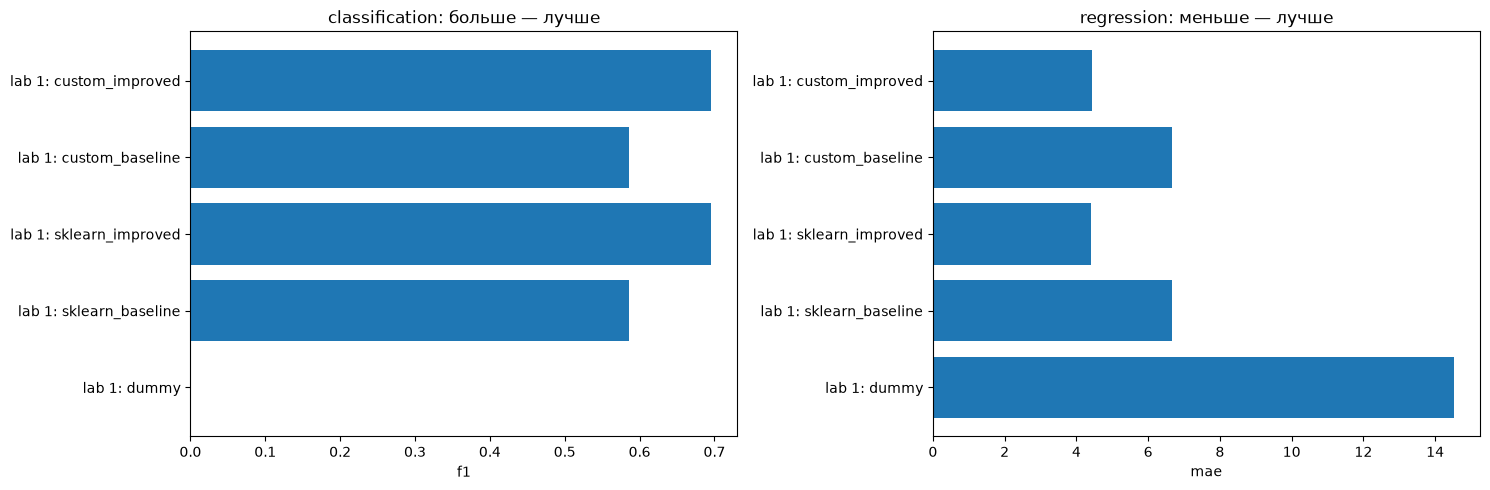

**classification:** наибольшее качество среди представленных моделей: sklearn_improved (lab 1), f1=0.69597.

**regression:** наибольшее качество среди представленных моделей: sklearn_improved (lab 1), mae=4.41873.

In [3]:
# Лучшие модели определяются по основной метрике каждой задачи; Dummy служит ориентиром.
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
for ax, task, score in zip(axes, ["classification", "regression"], ["f1", "mae"]):
    group = results[results.task == task].copy()
    labels = "lab " + group.lab.astype(str) + ": " + group.model
    ax.barh(labels, group[score])
    ax.set(xlabel=score, title=f"{task}: {'больше' if score == 'f1' else 'меньше'} — лучше")
plt.tight_layout()
plt.show()
for task, group in results[results.stage != "dummy"].groupby("task"):
    score = "f1" if task == "classification" else "mae"
    winner = group.loc[group[score].idxmax() if score == "f1" else group[score].idxmin()]
    display(Markdown(f"**{task}:** наибольшее качество среди представленных моделей: {winner['model']} (lab {winner['lab']}), {score}={winner[score]:.5f}."))

### Выводы

Улучшение предобработки и подбор параметров повысили качество KNN в обеих задачах:
F1 классификации вырос с 0,58593 до 0,69597, MAE регрессии снизилась с 6,66750 до 4,41873 МПа.
Для регрессии R² увеличился с 0,74070 до 0,85701.

В классификации собственные реализации и соответствующие модели sklearn дали одинаковые классы.
В регрессии результаты также близки: MAE улучшенной собственной модели составила 4,42176 МПа.
Небольшое расхождение связано с выбором соседа при практически равных расстояниях на границе k.

Собственная реализация уступила sklearn по скорости предсказания. Следовательно, при одинаковой
постановке обе реализации дают близкое качество, но различаются вычислительной эффективностью.
Выводы относятся к выбранным датасетам и одному контрольному разбиению.